# interpretacja wyników modeli (np. SHAP, feature importance).

# 1.Explainability - what is it?

Machine learning models function like "black box" - we do not really know what happens "inside" them, we just get some final result being culmination of thousands of mathematical operations. Explainability is, like the name suggests, explaining why we get such result and not something else. It can be compared to opening the black box and retrieving information from it.

In the context of recommendation engine, explainability is clarifying why something was recommended to the user. In our case, it explains why a particular movie was recommended (we can often see this mechanism on streaming sites where we are given the explanation, e.g. "We recommend $\textit{Shrek}$ BECAUSE you watched and liked many animated fantasy movies." or "Users like you enjoyed $\textit{Shrek}$.")

In order to explain the result, we use feature importance and the SHAP values.

#### Feature importance and SHAP

One of the most important term in explainability is "feature importance" - it explains the result globally. Feature importance is an answer to question: "What features in the dataset are globally the most important for the model?". It indicates a trend in the whole system, that is why we say it is global. For example, if our model recommends movies to users, the feature importance algorithm indicates that movie's genre is more important than filming location. However, this algorithm does not explicitly explain why such result was obtained - as we marked earlier, it only shows some trend.

On the other hand, SHAP analyses data locally - it focuses only on one observation. It clearly explains why such result was given at the end. SHAP value is a numerical value explaining the final movie recommendation. The absolute SHAP value shows us how much a single feature affected the prediction. For example, if a noir movie about mafia in New York is recommended to the user, the SHAP explains how much each feature (noir, mafia, New York) contributes to this answer.

# 2.Code

## Imprting libraries

In [2]:
import sys
import os

# we add path to .py files so that we can access the methods from src
project_path = os.path.abspath('../src')

if project_path not in sys.path:
    sys.path.append(project_path)

In [3]:
from data_loader import read_csv_files, cleaning_raw_data
from features import merge_movies_with_tags, build_content_matrix, prepare_cf_data, cf_to_numpy
from models import MF_SGD, content_based_scores, get_cf_scores, hybrid_model_recommendations
from explainability import RecommenderExplainer
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Preparing data

In [4]:
links, movies, ratings, tags = read_csv_files()
links, movies, ratings, tags = cleaning_raw_data(links, movies, ratings, tags)
merged_movies = merge_movies_with_tags(movies, tags)
matrix, vectorizer = build_content_matrix(merged_movies)

### Spliting into training and testing sets

In [5]:
train_df, test_df, user_map, movie_map = prepare_cf_data(ratings)
train_users, train_items, train_ratings, _, _, _ = cf_to_numpy(train_df, test_df)

### Training CF model

In [6]:
n_users = len(user_map)
n_items = len(movie_map)
sgd_model = MF_SGD(k=20, epochs=1)  # 3 epochs for testing
sgd_model.fit(train_users, train_items, train_ratings, n_users, n_items)

[cf-sgd] Epoch 1: RMSE = 0.8896


## Calling $\texttt{RecommenderExplainer}$ class

### Choosing models and user

In [7]:
models_to_test = ["cb", "cf", "hybrid"]

# we select random user 
target_user = list(user_map.keys())[0]

### Generating recommendations for each model and generating plots


 Model CB analysis:

Engine CB recommends Schindler's List (1993) for user 76916.
Explainability metrics for User 76916
Analysed features: 117 (all genres + top 100 tags)
Surrogate model credibility (R^2 Score): 0.9849


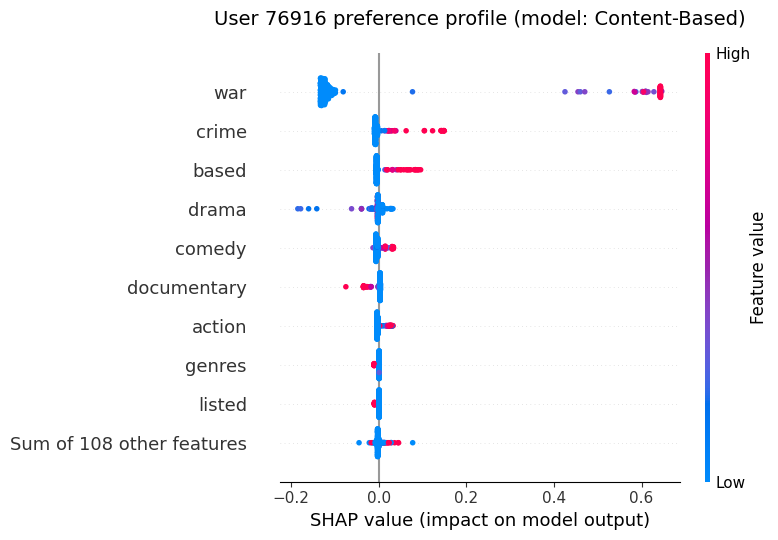

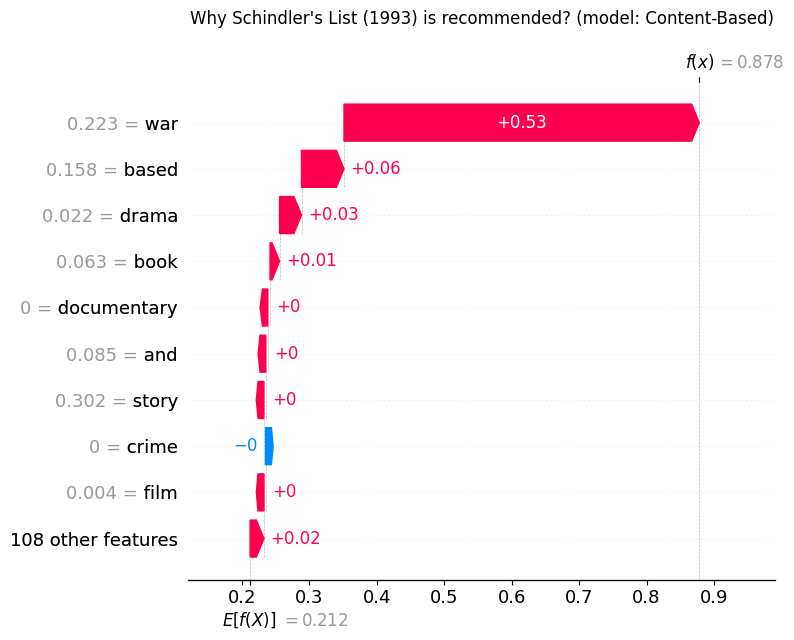

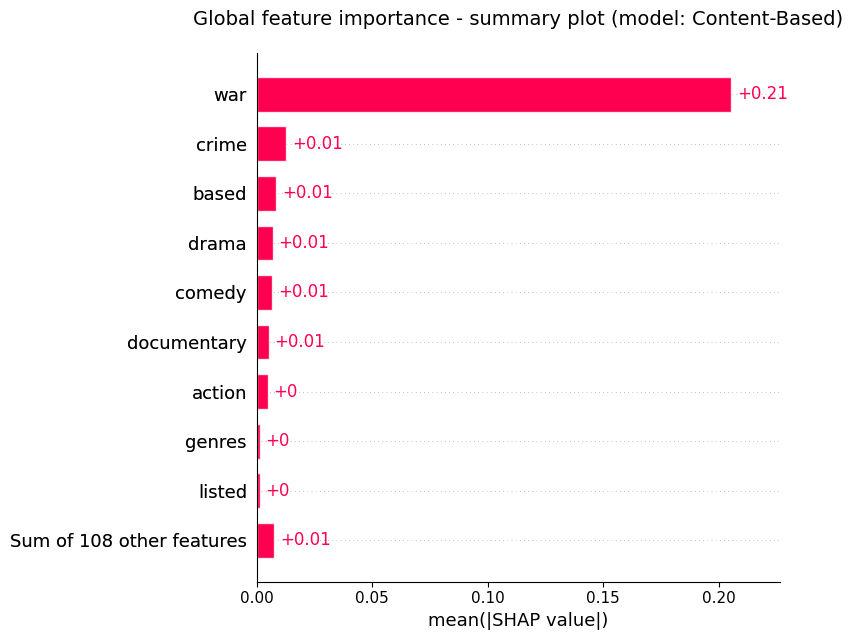

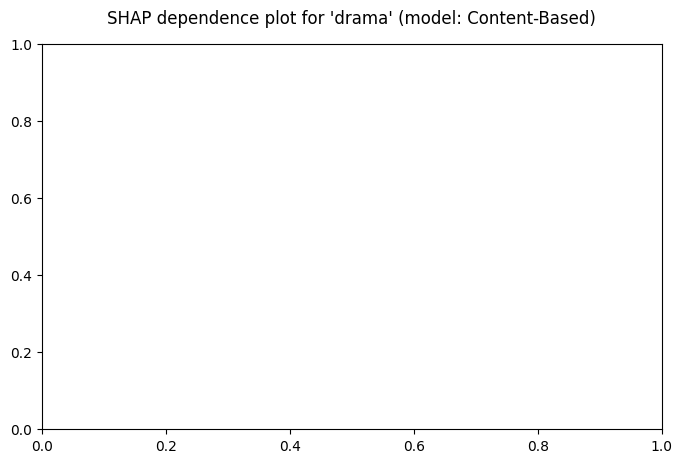

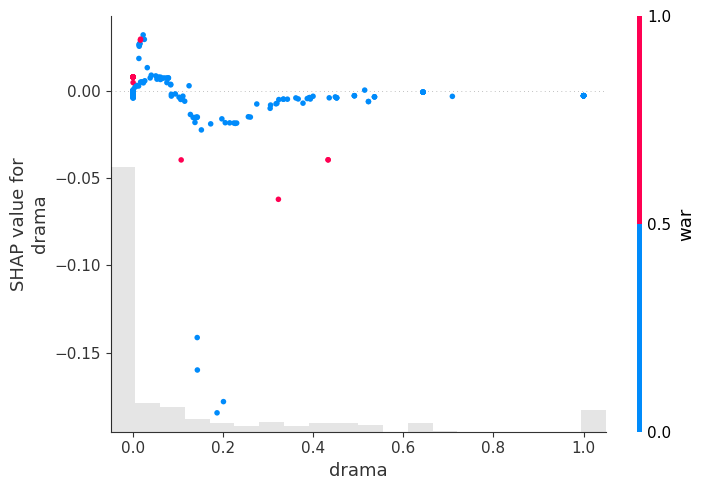


  Counterfactual analysis for: 'Schindler's List (1993)'
  Original recommendation evaluation (surogate model): 0.8782

[CRUCIAL FEATURES] Which of the following characteristics would most LOWER the recommendation?:
 - If this movie LOST feature 'war': The rating is lower by: -0.6653 -> New result: 0.2129
 - If this movie LOST feature 'documentary': The rating is lower by: -0.1123 -> New result: 0.7659
 - If this movie LOST feature 'based': The rating is lower by: -0.0511 -> New result: 0.8271
 - If this movie LOST feature 'drama': The rating is lower by: -0.0290 -> New result: 0.8493
 - If this movie LOST feature 'comedy': The rating is lower by: -0.0268 -> New result: 0.8514

What can be added/changed to make user like the movie more?:
 - If this movie HAD feature 'death': The rating is higer by 0.0058 -> New result: 0.8840
 - If this movie HAD feature 'plot': The rating is higer by 0.0023 -> New result: 0.8806
 - If this movie HAD feature 'clv': The rating is higer by 0.0005 -> New

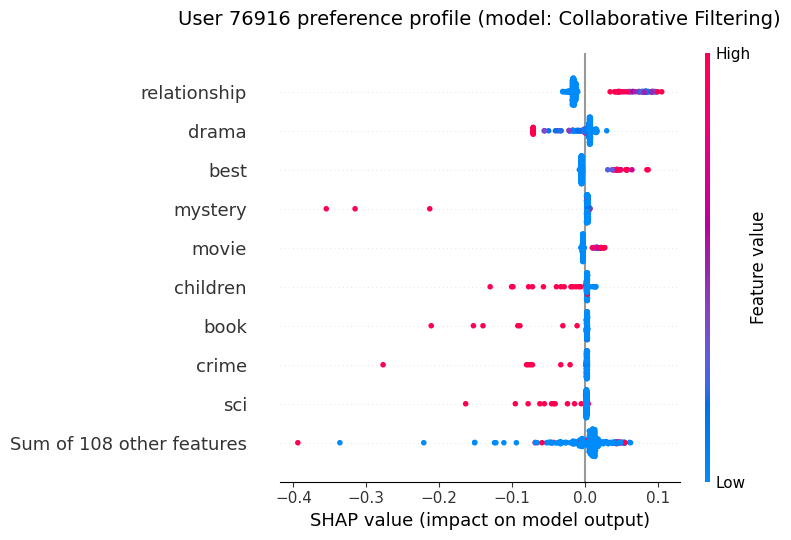

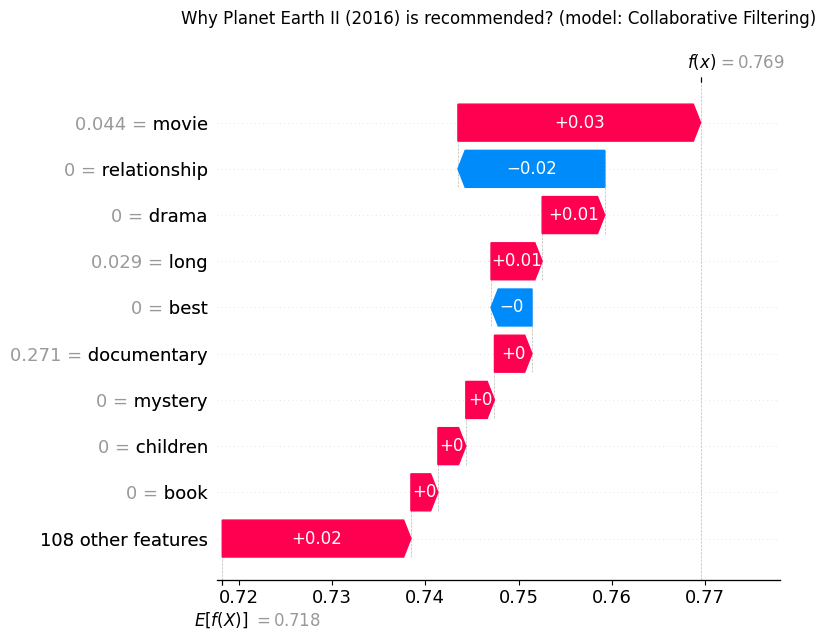

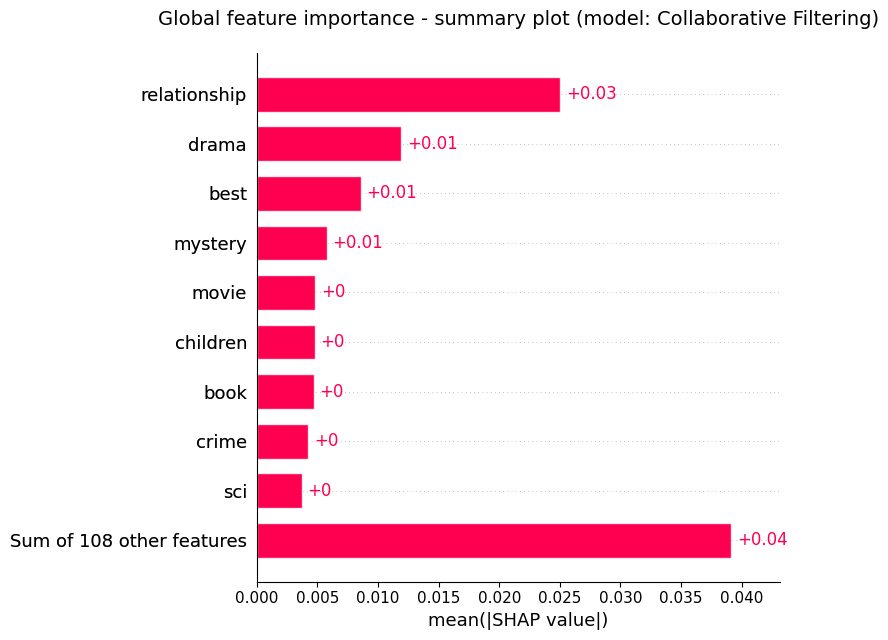

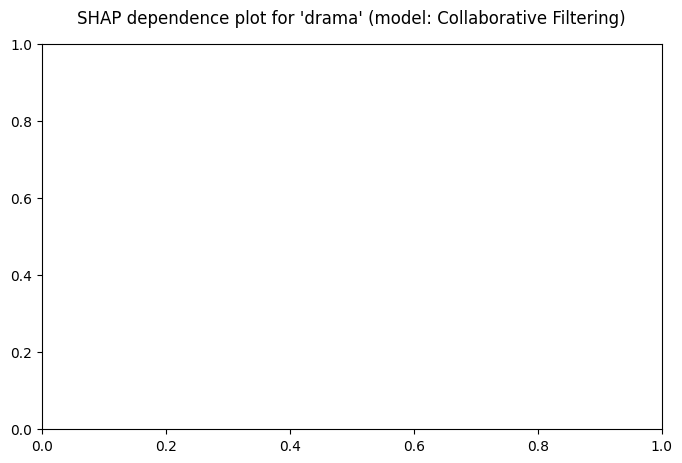

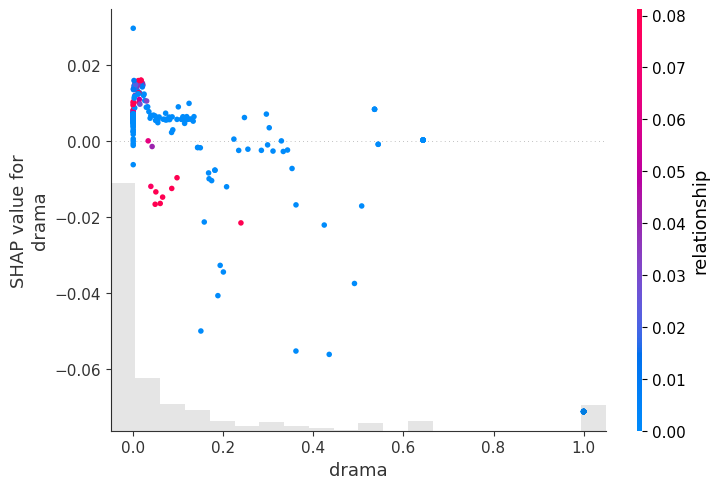


  Counterfactual analysis for: 'Planet Earth II (2016)'
  Original recommendation evaluation (surogate model): 0.7695

[CRUCIAL FEATURES] Which of the following characteristics would most LOWER the recommendation?:
 - If this movie LOST feature 'sex': The rating is lower by: -0.3988 -> New result: 0.3707
 - If this movie LOST feature 'mystery': The rating is lower by: -0.3129 -> New result: 0.4566
 - If this movie LOST feature 'crime': The rating is lower by: -0.2794 -> New result: 0.4901
 - If this movie LOST feature 'time': The rating is lower by: -0.2195 -> New result: 0.5500
 - If this movie LOST feature 'book': The rating is lower by: -0.2013 -> New result: 0.5682

What can be added/changed to make user like the movie more?:
 - If this movie HAD feature 'relationship': The rating is higer by 0.0744 -> New result: 0.8439
 - If this movie HAD feature 'best': The rating is higer by 0.0466 -> New result: 0.8161
 - If this movie HAD feature 'criterion': The rating is higer by 0.0088 -

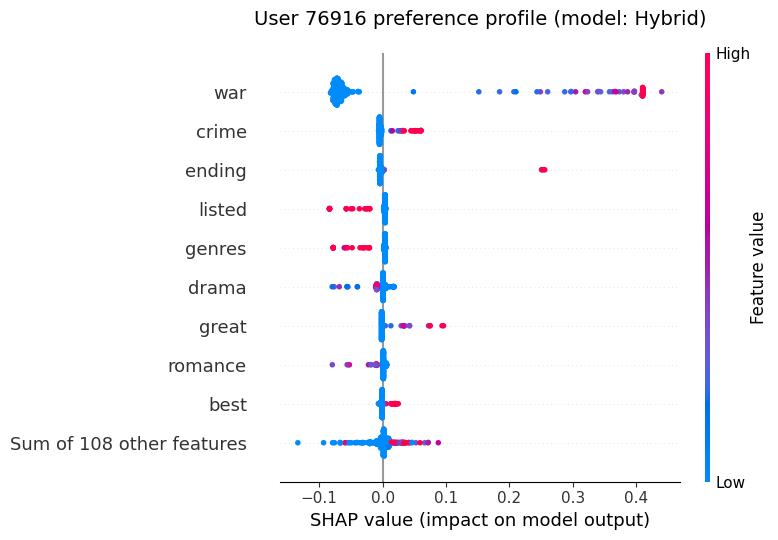

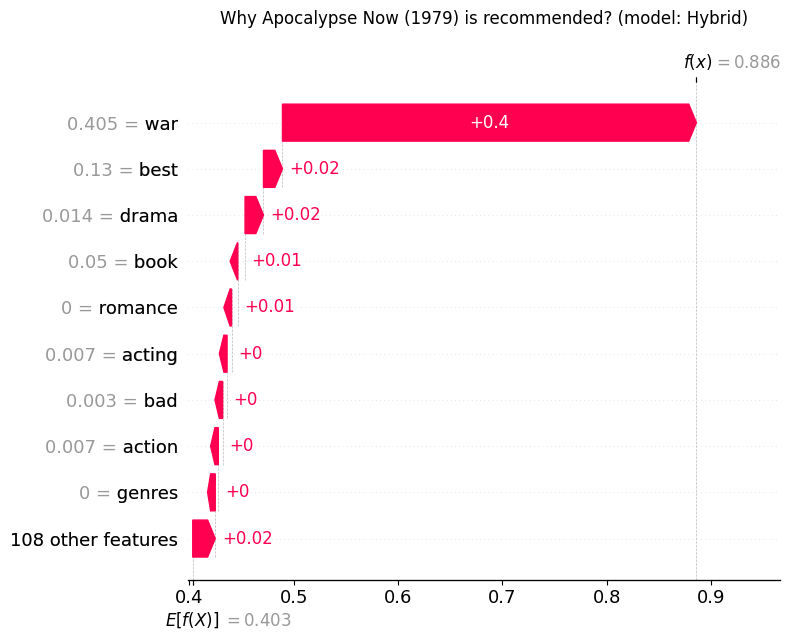

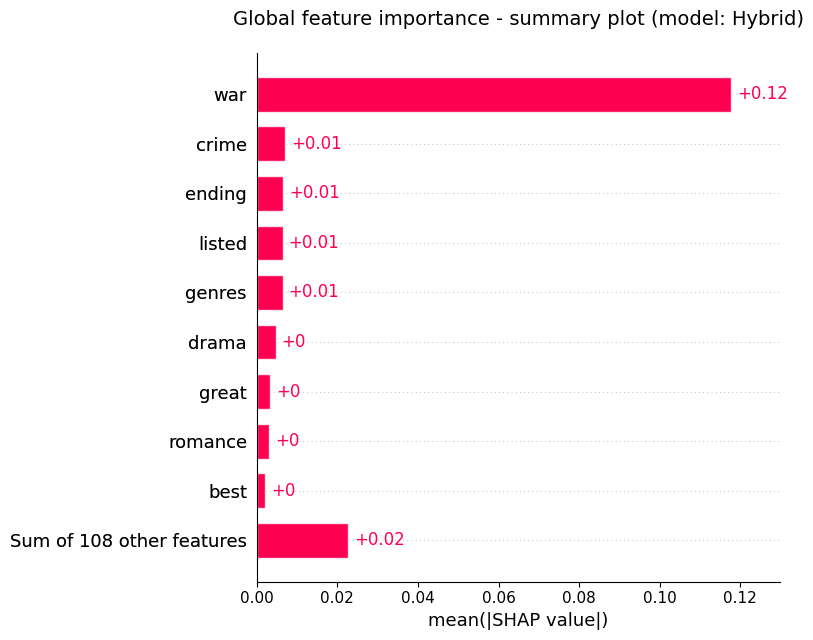

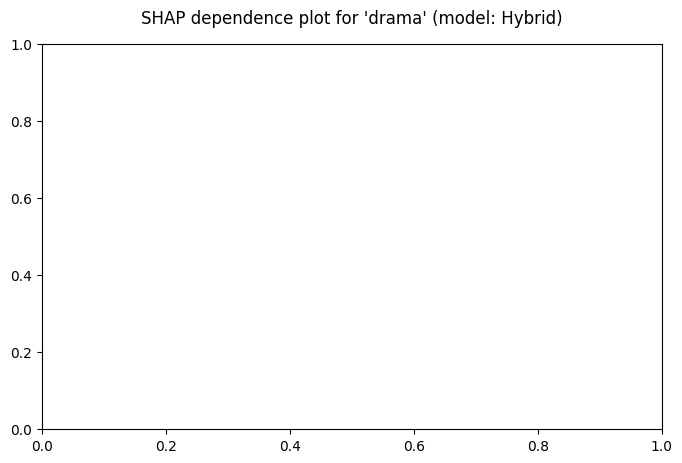

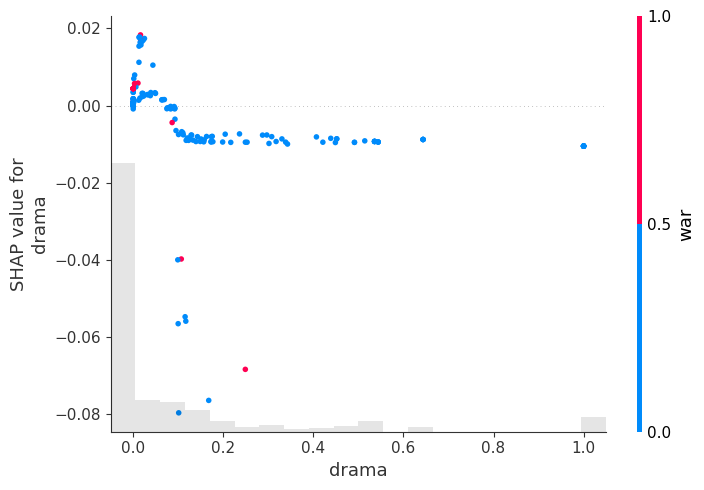


  Counterfactual analysis for: 'Apocalypse Now (1979)'
  Original recommendation evaluation (surogate model): 0.8859

[CRUCIAL FEATURES] Which of the following characteristics would most LOWER the recommendation?:
 - If this movie LOST feature 'war': The rating is lower by: -0.4895 -> New result: 0.3964
 - If this movie LOST feature 'romance': The rating is lower by: -0.1362 -> New result: 0.7497
 - If this movie LOST feature 'world': The rating is lower by: -0.0992 -> New result: 0.7867
 - If this movie LOST feature 'genres': The rating is lower by: -0.0840 -> New result: 0.8019
 - If this movie LOST feature 'listed': The rating is lower by: -0.0673 -> New result: 0.8186

What can be added/changed to make user like the movie more?:
 - If this movie HAD feature 'white': The rating is higer by 0.0020 -> New result: 0.8879
 - If this movie HAD feature 'story': The rating is higer by 0.0015 -> New result: 0.8874
 - If this movie HAD feature 'and': The rating is higer by 0.0013 -> New res

In [10]:
for model in models_to_test:
    print(f"\n Model {model.upper()} analysis:")

    # we generate recommendations for each model
    # Content-Based model
    if model == "cb":
        cb_recommendation = content_based_scores(target_user, train_df, merged_movies, matrix)
        best_movie = merged_movies.iloc[np.argmax(cb_recommendation)]['title']
    # Collaborative Filtering model
    elif model == "cf":
        cf_recommendation = get_cf_scores(sgd_model, target_user, user_map, movie_map, merged_movies)
        best_movie = merged_movies.iloc[np.argmax(cf_recommendation)]['title']
    # Hybrid model
    else:
        hybrid_recommendation = hybrid_model_recommendations(user_id=target_user, ratings=train_df,movies=merged_movies, matrix=matrix, cf_model=sgd_model, user_map=user_map, movie_map=movie_map, alpha=0.4, top_n=5)

        # we choose the movie rated as the best (number 1) in recommendation ranking;
        # the code is adapted to whether we use a DataFrame or a list
        if isinstance(hybrid_recommendation, pd.DataFrame):
            best_movie = hybrid_recommendation.iloc[0]['title']
        else:
            # in case of a list
            best_movie = hybrid_recommendation[0]

    print(f"\nEngine {model.upper()} recommends {best_movie} for user {target_user}.")
  
    # we initialize the explainer
    explainer = RecommenderExplainer(
        user_id=target_user,
        ratings=train_df,
        movies=merged_movies,
        matrix=matrix,
        vectorizer=vectorizer,
        cf_model=sgd_model,
        user_map=user_map,
        movie_map=movie_map,
        alpha=0.4,
        mode=model
    )

    # we match the interpretable surrogate model
    explainer.prepare_surrogate(sample_size=300)

    # we create beeswarm plot (user preference profile)
    # the plots explains which words/genres raise the user's rating and which words/genres lower the user's rating
    explainer.plot_global_explanation(max_display=10)
    plt.show()

    # we create waterfall plot (user preference profile)
    explainer.explain_specific_movie(best_movie)    
    plt.show()

    # we create global feature importance plot (summary plot)
    explainer.plot_summary_importance(max_display=10)
    plt.show()

    # we create dependence plot
    explainer.plot_dependence('drama')
    plt.show()

    # we initialize couterfactual analysis
    explainer.explain_counterfactual(best_movie)
    plt.show()

# 3.Plots interpretation

### What are beeswarm plots?

Beeswarm plots, in general, tell us about about the importnace or contibution of the features for the whole dataset. It answers the question: "What raises, and what lowers the final rating?". The beeswarm plots consists of two orthogonal lines: the vertical line is the feature list, ordered from the most important for the model (up) to the least important for the model (down); the horizontal line, the SHAP value, is scale of influence on the model, where the middle (SHAP value equal 0) means "neutral", right hand-side means "raising the final rating" and left hand-side means "lowering the final rating". Dots' color is "feature importance" (red dot - high importance, blue dot - low importance). Foe example, many red dots on negativs semi-axis and blue dots on positive semi-axis means "high values of this feature have a high negative contribution on the prediction, while low values have a high positive contribution".

In this case, beeswarm plot is user's preference profile and it answers the question: "What this user likes and dislikes in movies?". The features are, obviously, ordered from the most important to the least important on the vertical semi-axis. SHAP values in the contex of recommendation can be interpreted as follows:
- middle: the user is indifferent whether this feature appears or not in the movie;
- positive semi-axis: the user likes this feature (it raises movie's final rating);
- negative semi-axis: the user dislikes this feature (it lowers movie's final rating).

Dots' color can be interpreted as:
- red dot: the movie has particular feature (e.g. its genre is Western);
- blue dot: the movie does not have particular feature.

#### Example

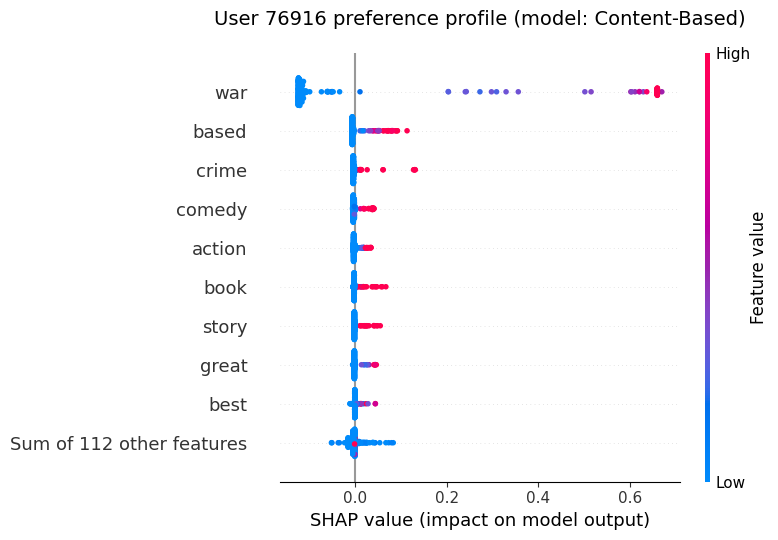

We can see that many red dots appear on the right hand-side and blue dots on the left hand-side. This means that a movie having feature $\textit{War}$ (whether it is genre or tag) will be appreciated by the user, while movies without this feature (blue dots mean "not having the feature") will be disliked by the user. We can also see that when a movie is based on true story ot contains crime or comedy elements (lines 2 - 4),  the user will rather like such movie; however, if such elements do not appear in a movie, this will not lower the user's rating (he is indifferent about these features' absence).

### What are waterfall plots?

Waterfall plot reveals the individual contribution of each feature on the output of the model, for each observation. We must emphasize that waterfall plots are valid for one observation only - with other data points the plot would change. Waterfall plots answer the question: "Why is the final prediction as such?". There are two orthogonal axes: the vertical one is the list of features ordered from the most contributing to the least contributiong; the x-axis is has the values of the target variable. Then, $E[f(x)]$ is the expected value of the target variable (in other words "starting point" or "the mean of all predictions"); $f(x)$ is the predicted value of the model. The arrows represent whether the final prediction is raised or lowered by particular feature - red right-oriented arrow means "this feature raises the final prediction", blue left-oriented arrow means "this feature lowers the final prediction".

In our case, the waterfall plot is an answer to question: "Why this particular movie was recommender to the user?". The features are, once again, ordered depending on their contribution. Here, $E[f(x)]$ is the mean of all movies in the databse - that is to say, if the model did not know anything about this movie, it would give the movie the rating equal $E[f(x)]$. $f(x)$ is, simply put, the final rating of the movie accordint to the model. The arrows indicate whether a feature raises or lowers the final rating.

#### Example

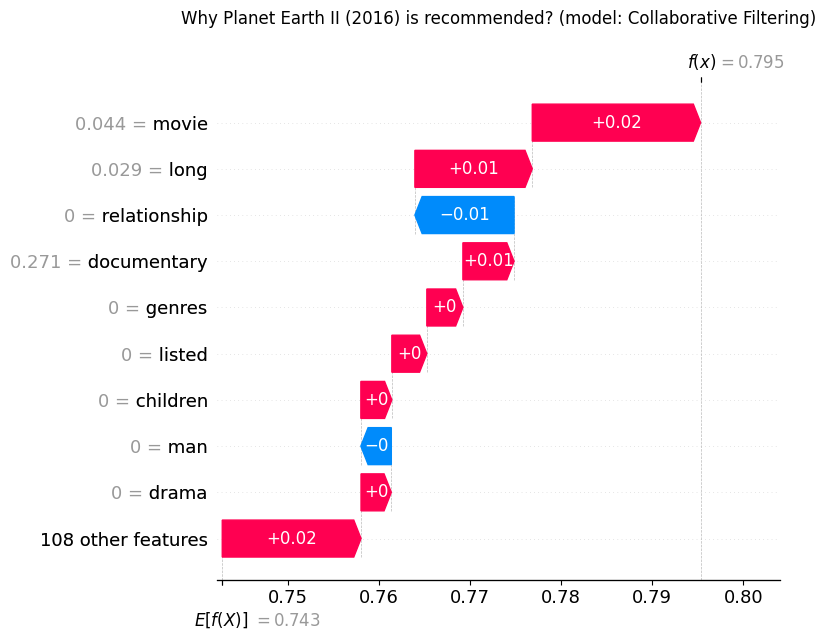

We can see that initially the SHAP value for movie $\textit{Planet Earth II}$ was 0.743. The waterfall plot clearly explains that some features (deoted as "108 other features") raises the result by 0.02 and the fact that this is a long movie (documentary) also adds, in summary, 0.04 points. However, the occurance of some kind of relationship (that the user apparently does not like) lowers the final result by 0.01 points. Finally, the SHAP value is 0.795.

### What are $R^2$ values in the contex of interpretability?

The SHAP model cannot "see everything" in the models used - that is why we use surrogate model based on Random Forest. The surrogate model imitates the recommendation engine and therefore gives predictions on its behalf. In such context, we must know how credible the surrogate model is - this is why the $R^2$ metrics is used. The $R^2$ result answers the question: "In how many percent the the surrogate model copies the original engine?".

High value of $R^2$ (80% - 100%) means that the surrogate model copies engine functionning almost perfectly, the beeswarm and waterfall plots are credible and we can trust the results. Mediocre $R^2$ value (40% - 80%) means that the surrogate model is not the best interpretation of original engine but it still "does its job" - we need to be sceptical when we analyse the plots. Low $R^2$ value (less than 40%) means that the surrogate model did not understand original engine's work and the obtained results are not credible, together with the plots.